X_train: (240, 64, 64), y_train: (240,)
X_val:   (80, 64, 64), y_val:   (80,)
X_test:  (80, 64, 64), y_test:  (80,)
X_test_corrupted:  (80, 64, 64), y_test:  (80,)
B:1 | Train Acc:0.7208 | Val Acc:0.4000 | Test (Clean):0.4875 | Test (Corrupt):0.2375 | OOB Acc:0.3409  | Disagree:0.0000   | Margin:1.0000 | Avg Unique Samples:152.00 / Out of:240
B:5 | Train Acc:0.9542 | Val Acc:0.5750 | Test (Clean):0.6625 | Test (Corrupt):0.3250 | OOB Acc:0.3410  | Disagree:0.7838   | Margin:0.2550 | Avg Unique Samples:148.20 / Out of:240
B:10 | Train Acc:0.9917 | Val Acc:0.7250 | Test (Clean):0.7500 | Test (Corrupt):0.5500 | OOB Acc:0.3957  | Disagree:0.7769   | Margin:0.2700 | Avg Unique Samples:152.00 / Out of:240
B:25 | Train Acc:1.0000 | Val Acc:0.8000 | Test (Clean):0.8375 | Test (Corrupt):0.5375 | OOB Acc:0.5833  | Disagree:0.7827   | Margin:0.2795 | Avg Unique Samples:150.12 / Out of:240
B:50 | Train Acc:1.0000 | Val Acc:0.8375 | Test (Clean):0.8625 | Test (Corrupt):0.5125 | OOB Acc:0.7292  | Dis

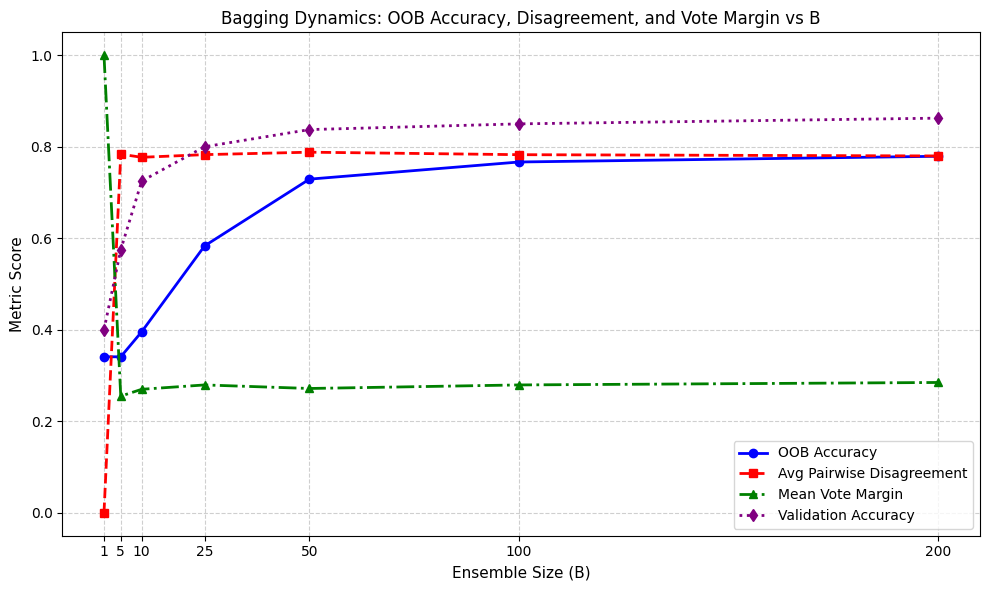

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q1_b_c.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

faces = fetch_olivetti_faces(shuffle=False)
X = faces.images
y = faces.target

height = X.shape[1]
width = X.shape[2]

split_data = np.load("olivetti_split_indices.npz")

train_idx = split_data["train"]
val_idx = split_data["val"]
test_idx = split_data["test"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_corrupted = X_test.copy()
X_test_corrupted[:, 24:40, 24:40] = 0.0

logger.info(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
logger.info(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
logger.info(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
logger.info(f"X_test_corrupted:  {X_test_corrupted.shape}, y_test:  {y_test.shape}")




X_train = X_train.reshape(-1, height * width)
X_val = X_val.reshape(-1, height * width)
X_test = X_test.reshape(-1, height * width)
X_test_corrupted = X_test_corrupted.reshape(-1, height * width)

seed = 260007

n_train = len(X_train)
B_values = [1, 5, 10, 25, 50, 100, 200]

def ensemble_predict(preds_list):
    preds_matrix = np.array(preds_list)
    num_samples = preds_matrix.shape[1]
    
    majority_votes = np.zeros(num_samples, dtype=int)
    
    for sample_idx in range(num_samples):
        column_votes = preds_matrix[:, sample_idx]
        classes, counts = np.unique(column_votes, return_counts=True)
        majority_votes[sample_idx] = classes[np.argmax(counts)]
        
    return majority_votes

oob_accuracies = []
disagreements = []
vote_margins = []
val_accuracies = []

for B in B_values:
    train_preds = []
    val_preds = []
    test_preds = []
    test_corrupted_preds = []
    unique_counts = []
    
    trees = []
    oob_masks = []

    rng = np.random.default_rng(seed=seed)

    for b in range(B):
        bootstrap_indices = rng.choice(n_train, size=n_train, replace=True)
        
        unique_counts.append(len(np.unique(bootstrap_indices)))
        
        in_bag = np.zeros(n_train, dtype=bool)
        in_bag[bootstrap_indices] = True
        oob_masks.append(~in_bag)

        X_bootstrap_samples, y_bootstrap_samples = X_train[bootstrap_indices], y_train[bootstrap_indices]

        clf = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=seed + b)
        clf.fit(X_bootstrap_samples, y_bootstrap_samples)
        trees.append(clf)

        train_preds.append(clf.predict(X_train))
        val_preds.append(clf.predict(X_val))
        test_preds.append(clf.predict(X_test))
        test_corrupted_preds.append(clf.predict(X_test_corrupted))

    train_acc = np.mean(ensemble_predict(train_preds) == y_train)
    val_acc = np.mean(ensemble_predict(val_preds) == y_val)
    test_acc = np.mean(ensemble_predict(test_preds) == y_test)
    test_corr_acc = np.mean(ensemble_predict(test_corrupted_preds) == y_test)
    avg_unique = np.mean(unique_counts)
    
    val_accuracies.append(val_acc)

    oob_correct = 0
    oob_total_evals = 0
    
    for i in range(n_train):
        oob_tree_indices = [b_idx for b_idx in range(B) if oob_masks[b_idx][i]]
        
        if len(oob_tree_indices) > 0:
            oob_preds = [trees[b_idx].predict(X_train[i:i+1])[0] for b_idx in oob_tree_indices]
            classes, counts = np.unique(oob_preds, return_counts=True)
            oob_winner = classes[np.argmax(counts)]
            
            if oob_winner == y_train[i]:
                oob_correct += 1
            oob_total_evals += 1
            
    oob_acc = oob_correct / oob_total_evals if oob_total_evals > 0 else 0.0
    oob_accuracies.append(oob_acc)

    val_preds_matrix = np.array(val_preds)
    if B == 1:
        avg_disagreement = 0.0
    else:
        num_pairs = 0
        total_disagreement = 0.0
        for j in range(B):
            for k in range(j + 1, B):
                disagreement = np.mean(val_preds_matrix[j] != val_preds_matrix[k])
                total_disagreement += disagreement
                num_pairs += 1
        avg_disagreement = total_disagreement / num_pairs
    disagreements.append(avg_disagreement)

    margins = []
    num_val_samples = len(X_val)
    
    for sample_idx in range(num_val_samples):
        column_votes = val_preds_matrix[:, sample_idx]
        classes, counts = np.unique(column_votes, return_counts=True)
        sorted_counts = np.sort(counts)[::-1]
        
        winner_count = sorted_counts[0]
        runner_up_count = sorted_counts[1] if len(sorted_counts) > 1 else 0
        
        margin = (winner_count - runner_up_count) / B
        margins.append(margin)
        
    mean_margin = np.mean(margins)
    vote_margins.append(mean_margin)

    logger.info(f"B:{B} | Train Acc:{train_acc:.4f} | Val Acc:{val_acc:.4f} | Test (Clean):{test_acc:.4f} | Test (Corrupt):{test_corr_acc:.4f} | OOB Acc:{oob_acc:.4f}  | Disagree:{avg_disagreement:.4f}   | Margin:{mean_margin:.4f} | Avg Unique Samples:{avg_unique:.2f} / Out of:{n_train}")

best_idx = np.argmax(val_accuracies)
best_B = B_values[best_idx]
best_val_acc = val_accuracies[best_idx]

logger.info("=" * 90)
logger.info(f"Optimal Ensemble Size Selected: B = {best_B} (Validation Accuracy = {best_val_acc:.4f})")
logger.info("=" * 90)

prob_selected = 1.0 - ((1.0 - 1.0 / n_train) ** n_train)
expected_distinct = n_train * prob_selected

logger.info(f"\nTheoretical Expected Unique Samples per Bootstrap (N={n_train}): {expected_distinct:.2f} ({prob_selected*100:.2f}%)")
logger.info(f"Comparison: Empirical Average Unique Samples = {avg_unique:.2f} vs Theoretical = {expected_distinct:.2f}\n")

plt.figure(figsize=(10, 6))

plt.plot(B_values, oob_accuracies, 'o-', color='blue', label='OOB Accuracy', linewidth=2)
plt.plot(B_values, disagreements, 's--', color='red', label='Avg Pairwise Disagreement', linewidth=2)
plt.plot(B_values, vote_margins, '^-.', color='green', label='Mean Vote Margin', linewidth=2)
plt.plot(B_values, val_accuracies, 'd:', color='purple', label='Validation Accuracy', linewidth=2)

#plt.xscale('log')
plt.xticks(B_values, labels=[str(b) for b in B_values])
plt.xlabel('Ensemble Size (B)', fontsize=11)
plt.ylabel('Metric Score', fontsize=11)
plt.title('Bagging Dynamics: OOB Accuracy, Disagreement, and Vote Margin vs B', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("q1_b_c_bagging_odv.png", dpi=300, bbox_inches="tight")
plt.show()